In [6]:
import os
import pandas as pd
import scanpy as sc

In [3]:
in_dir = '../../results/07_scTM/01_run_scTM'
out_dir = '../../results/07_scTM/03_compare_topic'

os.makedirs(out_dir, exist_ok=True)

In [7]:
adata = sc.read_h5ad(f"{in_dir}/scTM_15topics.h5ad")

/Users/zhijianli/miniforge3/envs/zl_src/lib/python3.12/site-packages/anndata/_core/anndata.py:1823: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [8]:
adata.obs.head()

,in_tissue,array_row,array_col,n_genes_by_counts,log1p_n_genes_by_counts,total_counts,log1p_total_counts,pct_counts_in_top_50_genes,pct_counts_in_top_100_genes,pct_counts_in_top_200_genes,...,Topic6,Topic7,Topic8,Topic9,Topic10,Topic11,Topic12,Topic13,Topic14,Topic15
AACCAAGGTATCAGGC-1,1.0,38.0,104.0,7172,8.878079,22821.0,10.035480,14.359581,19.236668,25.695631,...,0.010489,0.008724,0.098326,0.010165,0.004213,0.013495,0.028029,0.011385,0.021691,0.016759
AACCGCCAGACTACTT-1,1.0,39.0,45.0,2854,7.956827,4843.0,8.485497,18.087962,23.291348,30.642164,...,0.038572,0.056372,0.031112,0.078582,0.021320,0.018775,0.092557,0.046845,0.136423,0.094581
AACGAATTGACCGGTT-1,1.0,35.0,39.0,3974,8.287780,7338.0,8.900958,13.654947,18.247479,25.361134,...,0.018967,0.034244,0.024975,0.104192,0.007572,0.015791,0.134996,0.054349,0.044915,0.182739
AACTCAACCTTGACCA-1,1.0,39.0,79.0,4307,8.368229,7605.0,8.936692,13.070348,17.238659,23.418803,...,0.017109,0.076412,0.034796,0.026937,0.010615,0.046106,0.026979,0.039900,0.050710,0.016835
AACTGCCTCGATAGGT-1,1.0,37.0,61.0,5423,8.598589,10371.0,9.246865,9.970109,13.740237,19.554527,...,0.048857,0.109826,0.025627,0.025339,0.010334,0.043608,0.067553,0.069344,0.071755,0.034675


In [17]:
df = adata.obs[['library_id', 
                'Topic1', 'Topic2', 'Topic3', 'Topic4', 'Topic5', 
                'Topic6', 'Topic7', 'Topic8', 'Topic9', 'Topic10', 
                'Topic11', 'Topic12', 'Topic13', 'Topic14', 'Topic15']]
df['library_id'] = df['library_id'].apply(lambda x: x.split('_')[0])

/var/folders/rg/6bkp4j2s36nd_4x36jzgp1dm0000gn/T/ipykernel_49245/907190460.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['library_id'] = df['library_id'].apply(lambda x: x.split('_')[0])


In [18]:
df['library_id'].unique()

array(['15837', '15852', '16512', '21022', '8262', 'B23-03794-5',
       'B23-05785-7-1', 'B23-05785-7-2', 'X1842', 'X1845', 'X1899',
       'X1912'], dtype=object)

In [46]:
# get average topic score for each library
df_avg = df.groupby('library_id').mean()

df_avg['library_id'] = df_avg.index
df_avg = df_avg.melt(id_vars=['library_id'], 
                      var_name='topic', value_name='score')

df_avg['condition'] = df_avg['library_id']
df_avg['condition'] = df_avg['condition'].str.replace("15837", "SRC")
df_avg['condition'] = df_avg['condition'].str.replace("15852", "SRC")
df_avg['condition'] = df_avg['condition'].str.replace("16512", "SRC")
df_avg['condition'] = df_avg['condition'].str.replace("21022", "SRC")
df_avg['condition'] = df_avg['condition'].str.replace("8262", "SRC")
df_avg['condition'] = df_avg['condition'].str.replace("B23-03794-5", "Normal")
df_avg['condition'] = df_avg['condition'].str.replace("B23-05785-7-1", "Normal")
df_avg['condition'] = df_avg['condition'].str.replace("B23-05785-7-2", "Normal")
df_avg['condition'] = df_avg['condition'].str.replace("X1842", "LN")
df_avg['condition'] = df_avg['condition'].str.replace("X1845", "LN")
df_avg['condition'] = df_avg['condition'].str.replace("X1899", "LN")
df_avg['condition'] = df_avg['condition'].str.replace("X1912", "LN")

In [47]:
df_avg.head()

,library_id,topic,score,condition
0,15837,Topic1,0.096655,SRC
1,15852,Topic1,0.066387,SRC
2,16512,Topic1,0.033307,SRC
3,21022,Topic1,0.055870,SRC
4,8262,Topic1,0.115426,SRC


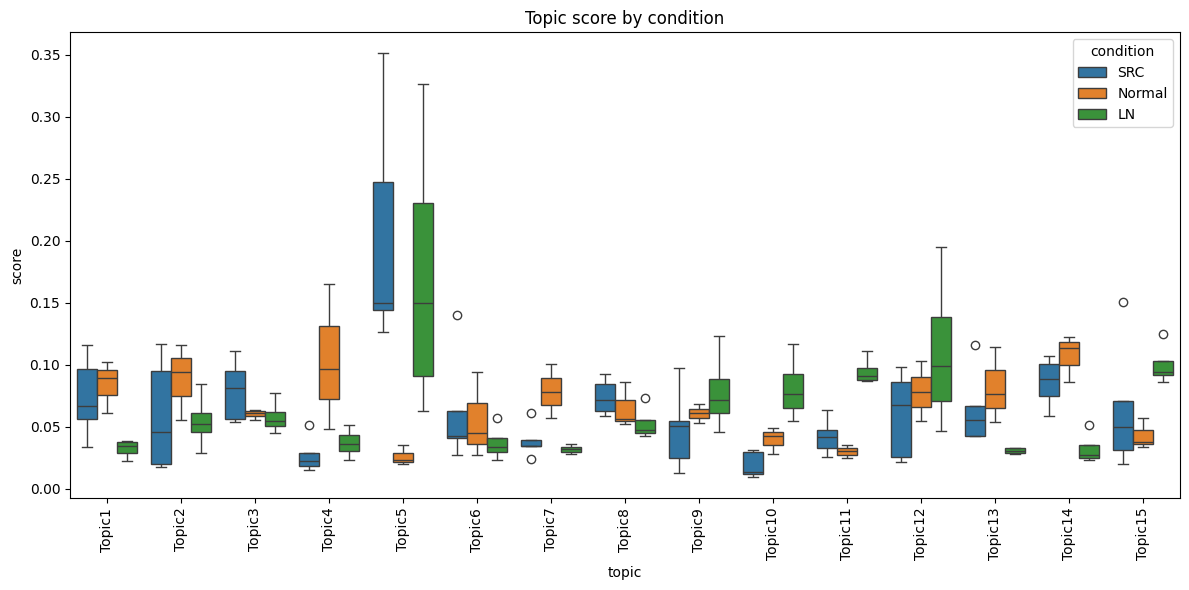

In [49]:
# plot boxplot of topic score for each condition
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sns.boxplot(x='topic', y='score', hue='condition', data=df_avg)
plt.xticks(rotation=90)
plt.title('Topic score by condition')
plt.tight_layout()

In [50]:
df_avg

,library_id,topic,score,condition
0,15837,Topic1,0.096655,SRC
1,15852,Topic1,0.066387,SRC
2,16512,Topic1,0.033307,SRC
3,21022,Topic1,0.055870,SRC
4,8262,Topic1,0.115426,SRC
...,...,...,...,...
175,B23-05785-7-2,Topic15,0.033508,Normal
176,X1842,Topic15,0.095155,LN
177,X1845,Topic15,0.085791,LN
178,X1899,Topic15,0.093482,LN


In [16]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

In [ ]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']